In [1]:
from pathlib import Path
import sys

if Path('/content').exists():
    ROOT = Path('/content/woodbench')
else:
    ROOT = Path.cwd()

# nbconvert may execute with the notebook directory as cwd; walk up to repo root.
if not (ROOT / "src").exists():
    ROOT = next(
        (parent for parent in [ROOT, *ROOT.parents] if (parent / "src").exists()),
        ROOT,
    )

sys.path.insert(0, str(ROOT))

# Phase 1 — FLOPs and inference-time benchmark

Notebook này hoàn tất hai mục efficiency còn lại trong `WoodID_plan.md` cho 5 backbone. Thiết lập chuẩn là ảnh `224×224`, batch size 1, 20 warm-up và 100 lần đo. Notebook ưu tiên CUDA nếu khả dụng, nếu không sẽ đo CPU và ghi đầy đủ metadata phần cứng.

Quy ước tính toán: THOP trả về MACs; báo cáo ghi cả GMACs và GFLOPs, với **1 MAC = 2 FLOPs** (một phép nhân và một phép cộng). Checkpoint Task B `main/seed_42` được load để xác minh kiến trúc và trọng số thực tế; FLOPs không phụ thuộc giá trị trọng số.

In [2]:
if Path('/content').exists():
    !pip install -q -r {ROOT}/requirements.txt

In [3]:
import io
import json
import os
import platform
import statistics
import time
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import pandas as pd
import timm
import torch
from thop import profile

from src.models.factory import BACKBONE_NAMES, create_model

INPUT_SIZE = (3, 224, 224)
BATCH_SIZE = 1
WARMUP_RUNS = 20
TIMED_RUNS = 100

EXPERIMENT_DIR = ROOT / "data" / "experiments"
CHECKPOINT_ROOT = EXPERIMENT_DIR / "Task-B" / "main" / "seed_42"
OUTPUT_DIR = EXPERIMENT_DIR / "phase_1" / "efficiency"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINTS = {
    "resnet50": CHECKPOINT_ROOT / "resnet50" / "resnet50_seed42_best.pth",
    "efficientnet_b3": CHECKPOINT_ROOT / "efficientnet_b3" / "efficientnet_b3_seed42_best.pth",
    "mobilenetv3_large": CHECKPOINT_ROOT / "mobilenetv3_large" / "mobilenetv3_large_seed42_best.pth",
    "convnext_tiny": CHECKPOINT_ROOT / "convnext_tiny" / "convnext_tiny_seed42_best.pth",
    "swin_tiny": CHECKPOINT_ROOT / "swin_tiny" / "swin_tiny_seed42_best.pth",
}

missing = [str(path) for path in CHECKPOINTS.values() if not path.exists()]
if missing:
    raise FileNotFoundError("Missing required checkpoints:\n" + "\n".join(missing))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"ROOT: {ROOT}")
print(f"Output: {OUTPUT_DIR}")
print(f"Device: {DEVICE}")
print(f"Runs: warm-up={WARMUP_RUNS}, timed={TIMED_RUNS}, batch={BATCH_SIZE}")

ROOT: /home/sakana/Code/ManifoldsTeam/woodbench
Output: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/efficiency
Device: cuda
Runs: warm-up=20, timed=100, batch=1


In [4]:
def load_checkpoint(path):
    try:
        payload = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        payload = torch.load(path, map_location="cpu")
    state_dict = payload.get("model_state_dict", payload)
    return payload, state_dict


def infer_num_classes(state_dict):
    preferred_suffixes = (
        "fc.weight",
        "classifier.weight",
        "head.fc.weight",
        "head.weight",
    )
    candidates = [
        (key, value)
        for key, value in state_dict.items()
        if torch.is_tensor(value) and value.ndim == 2 and key.endswith(preferred_suffixes)
    ]
    if not candidates:
        raise ValueError("Cannot infer classification head from checkpoint")
    key, tensor = candidates[-1]
    return int(tensor.shape[0]), key


def serialized_state_dict_size_mb(state_dict):
    buffer = io.BytesIO()
    torch.save(state_dict, buffer)
    return buffer.tell() / (1024 ** 2)


def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)


@torch.inference_mode()
def measure_latency(model, device, input_size, warmup_runs=20, timed_runs=100):
    sample = torch.randn(BATCH_SIZE, *input_size, device=device)
    for _ in range(warmup_runs):
        model(sample)
    synchronize(device)

    samples_ms = []
    for _ in range(timed_runs):
        synchronize(device)
        started = time.perf_counter_ns()
        model(sample)
        synchronize(device)
        samples_ms.append((time.perf_counter_ns() - started) / 1e6)

    ordered = sorted(samples_ms)
    p95_index = max(0, int(0.95 * len(ordered)) - 1)
    return {
        "latency_mean_ms": statistics.fmean(samples_ms) / BATCH_SIZE,
        "latency_std_ms": statistics.pstdev(samples_ms) / BATCH_SIZE,
        "latency_median_ms": statistics.median(samples_ms) / BATCH_SIZE,
        "latency_p95_ms": ordered[p95_index] / BATCH_SIZE,
        "throughput_images_s": BATCH_SIZE * 1000.0 / statistics.fmean(samples_ms),
    }


def benchmark_one(backbone, checkpoint_path):
    payload, state_dict = load_checkpoint(checkpoint_path)
    num_classes, head_key = infer_num_classes(state_dict)
    model = create_model(backbone, num_classes=num_classes, pretrained=False)
    incompatible = model.load_state_dict(state_dict, strict=True)
    if incompatible.missing_keys or incompatible.unexpected_keys:
        raise RuntimeError(f"Checkpoint mismatch for {backbone}: {incompatible}")

    model.eval()
    total_params = sum(parameter.numel() for parameter in model.parameters())
    trainable_params = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

    cpu_sample = torch.randn(BATCH_SIZE, *INPUT_SIZE)
    macs, thop_params = profile(model.cpu(), inputs=(cpu_sample,), verbose=False)
    if int(thop_params) != total_params:
        print(f"[Note] THOP parameter count differs for {backbone}: {thop_params} vs {total_params}")

    model = model.to(DEVICE)
    timing = measure_latency(model, DEVICE, INPUT_SIZE, WARMUP_RUNS, TIMED_RUNS)
    checkpoint_metrics = payload.get("metrics", {}) if isinstance(payload, dict) else {}

    row = {
        "model": backbone,
        "timm_model": BACKBONE_NAMES[backbone],
        "checkpoint": str(checkpoint_path.relative_to(ROOT)),
        "checkpoint_loaded": True,
        "checkpoint_head": head_key,
        "num_classes": num_classes,
        "input_shape": f"{BATCH_SIZE}x{INPUT_SIZE[0]}x{INPUT_SIZE[1]}x{INPUT_SIZE[2]}",
        "params": total_params,
        "params_m": total_params / 1e6,
        "trainable_params": trainable_params,
        "gmacs": macs / 1e9,
        "gflops_2_per_mac": 2 * macs / 1e9,
        "checkpoint_size_mb": checkpoint_path.stat().st_size / (1024 ** 2),
        "state_dict_size_mb": serialized_state_dict_size_mb(state_dict),
        "checkpoint_best_val_acc": payload.get("best_val_acc") if isinstance(payload, dict) else None,
        "checkpoint_val_acc": checkpoint_metrics.get("val_acc"),
        **timing,
    }
    del model, payload, state_dict, cpu_sample
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return row

In [5]:
results = []
for backbone, checkpoint_path in CHECKPOINTS.items():
    print(f"Benchmarking {backbone}...")
    row = benchmark_one(backbone, checkpoint_path)
    results.append(row)
    print(
        f"  {row['params_m']:.2f}M params | {row['gflops_2_per_mac']:.2f} GFLOPs | "
        f"{row['latency_mean_ms']:.2f} ± {row['latency_std_ms']:.2f} ms/image"
    )

results_df = pd.DataFrame(results)
display_columns = [
    "model", "num_classes", "params_m", "gmacs", "gflops_2_per_mac",
    "state_dict_size_mb", "latency_mean_ms", "latency_std_ms",
    "latency_p95_ms", "throughput_images_s",
]
results_df[display_columns].round(3)

Benchmarking resnet50...


  23.54M params | 8.26 GFLOPs | 3.09 ± 0.32 ms/image
Benchmarking efficientnet_b3...


[Note] THOP parameter count differs for efficientnet_b3: 10604897.0 vs 10722361


  10.72M params | 1.88 GFLOPs | 3.47 ± 0.31 ms/image
Benchmarking mobilenetv3_large...
[Note] THOP parameter count differs for mobilenetv3_large: 4177632.0 vs 4223809


  4.22M params | 0.43 GFLOPs | 1.88 ± 0.80 ms/image
Benchmarking convnext_tiny...


[Note] THOP parameter count differs for convnext_tiny: 27810257.0 vs 27833201


  27.83M params | 8.91 GFLOPs | 3.76 ± 0.48 ms/image
Benchmarking swin_tiny...


[Note] THOP parameter count differs for swin_tiny: 27509105.0 vs 27532427


  27.53M params | 8.74 GFLOPs | 4.70 ± 0.51 ms/image


,model,num_classes,params_m,gmacs,gflops_2_per_mac,state_dict_size_mb,latency_mean_ms,latency_std_ms,latency_p95_ms,throughput_images_s
0,resnet50,17,23.543,4.132,8.263,90.110,3.094,0.324,3.758,323.193
1,efficientnet_b3,17,10.722,0.938,1.877,41.419,3.474,0.315,3.909,287.811
2,mobilenetv3_large,17,4.224,0.215,0.431,16.303,1.882,0.801,2.720,531.253
3,convnext_tiny,17,27.833,4.455,8.910,106.239,3.762,0.478,4.557,265.783
4,swin_tiny,17,27.532,4.371,8.742,105.090,4.696,0.512,5.534,212.950


In [6]:
metadata = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "root": str(ROOT),
    "device_type": DEVICE.type,
    "device_name": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else platform.processor() or platform.machine(),
    "platform": platform.platform(),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "timm_version": timm.__version__,
    "cuda_version": torch.version.cuda,
    "torch_num_threads": torch.get_num_threads(),
    "batch_size": BATCH_SIZE,
    "input_size": list(INPUT_SIZE),
    "warmup_runs": WARMUP_RUNS,
    "timed_runs": TIMED_RUNS,
    "flops_convention": "THOP MACs; FLOPs = 2 * MACs (multiply + add)",
}

csv_path = OUTPUT_DIR / "efficiency_results.csv"
json_path = OUTPUT_DIR / "efficiency_results.json"
metadata_path = OUTPUT_DIR / "benchmark_metadata.json"

results_df.to_csv(csv_path, index=False)
json_path.write_text(json.dumps(results, indent=2), encoding="utf-8")
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print(f"Saved: {csv_path}")
print(f"Saved: {json_path}")
print(f"Saved: {metadata_path}")
metadata

Saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/efficiency/efficiency_results.csv
Saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/efficiency/efficiency_results.json
Saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/efficiency/benchmark_metadata.json


{'created_at_utc': '2026-07-23T13:36:37.800231+00:00',
 'root': '/home/sakana/Code/ManifoldsTeam/woodbench',
 'device_type': 'cuda',
 'device_name': 'NVIDIA GeForce RTX 3060',
 'platform': 'Linux-7.1.3-arch2-2-x86_64-with-glibc2.43',
 'python_version': '3.11.15',
 'torch_version': '2.12.0+cu130',
 'timm_version': '1.0.27',
 'cuda_version': '13.0',
 'torch_num_threads': 14,
 'batch_size': 1,
 'input_size': [3, 224, 224],
 'warmup_runs': 20,
 'timed_runs': 100,
 'flops_convention': 'THOP MACs; FLOPs = 2 * MACs (multiply + add)'}

Saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/efficiency/efficiency_comparison.png


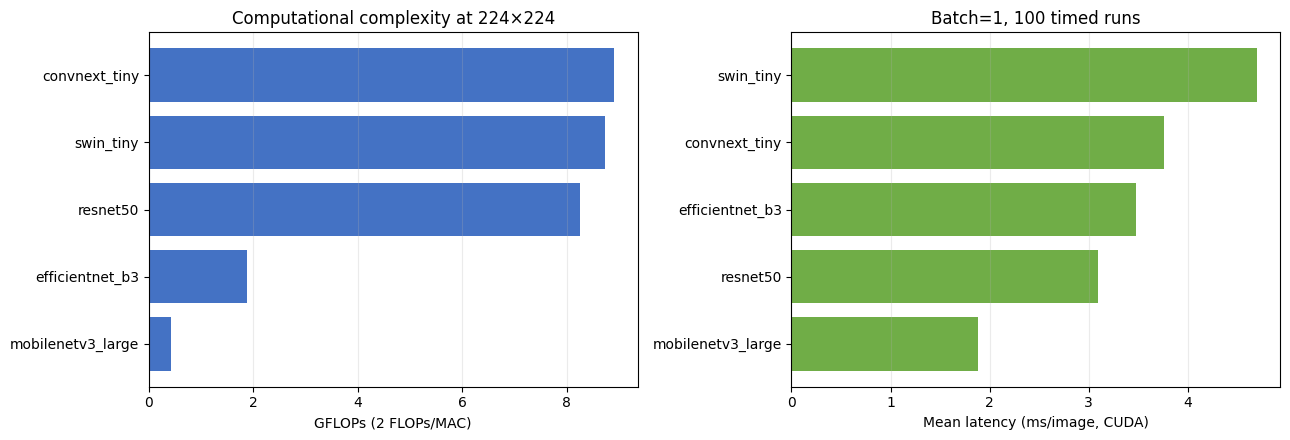

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

plot_df = results_df.sort_values("gflops_2_per_mac")
axes[0].barh(plot_df["model"], plot_df["gflops_2_per_mac"], color="#4472C4")
axes[0].set_xlabel("GFLOPs (2 FLOPs/MAC)")
axes[0].set_title("Computational complexity at 224×224")
axes[0].grid(axis="x", alpha=0.25)

plot_df = results_df.sort_values("latency_mean_ms")
axes[1].barh(plot_df["model"], plot_df["latency_mean_ms"], color="#70AD47")
axes[1].set_xlabel(f"Mean latency (ms/image, {DEVICE.type.upper()})")
axes[1].set_title(f"Batch=1, {TIMED_RUNS} timed runs")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
figure_path = OUTPUT_DIR / "efficiency_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
print(f"Saved: {figure_path}")
plt.show()

## Diễn giải

- So sánh latency chỉ có ý nghĩa khi giữ nguyên thiết bị, phiên bản phần mềm, batch size, input size và cách warm-up.
- `checkpoint_size_mb` gồm optimizer/scheduler và metadata phục vụ resume training; `state_dict_size_mb` phản ánh gần hơn dung lượng trọng số khi deployment.
- Để có số GPU dùng trong paper, chạy lại toàn bộ notebook trên cùng một GPU mục tiêu. Notebook sẽ tự chuyển sang CUDA và ghi model GPU vào metadata.
- Kết quả được benchmark với checkpoint Final-B head 17 lớp tại `data/experiments/Task-B/main/seed_42`, đúng phạm vi chính thức sau khi loại ba lớp thiếu dữ liệu.